### GITHUB LINK : https://github.com/Polymari/deep-learning-gslc

In [1]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import models, transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score, f1_score
from sklearn.metrics import classification_report, f1_score, accuracy_score
from collections import Counter
import numpy as np
import copy
import time
import torch
import pandas as pd
import matplotlib.pyplot as plt
import json
import random
import os

def set_seed(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

SEED = 42
set_seed(SEED)

CONFIG = {
    'batch_size': 32,
    'num_workers': 2 if torch.cuda.is_available() else 0,
    'img_size': 224,
    'patience': 4,
    'max_epochs': 20,
    'num_classes': 10,
    'seed': SEED
}



torch.cuda.is_available()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

trainval = torchvision.datasets.OxfordIIITPet("./root", split="trainval", download=True)
test = torchvision.datasets.OxfordIIITPet("./root", split="test", download=True)
print(trainval.bin_classes)
print(trainval.classes)

animal_classes = [
    "Abyssinian", "British Shorthair", "Egyptian Mau", "Persian", "Russian Blue",
    "Samoyed", "Pomeranian", "Shiba Inu", "American Bulldog", "Beagle"
]
class_to_idx = {name: i for i, name in enumerate(animal_classes)}
orig_to_new_idx = {trainval.classes.index(name): idx for name, idx in class_to_idx.items()}

all_image_paths = []
all_labels = []

for ds in [trainval, test]:
    for img_path, orig_lbl in zip(ds._images, ds._labels):
        if orig_lbl in orig_to_new_idx:
            all_image_paths.append(str(img_path))
            all_labels.append(orig_to_new_idx[orig_lbl])

print(f"Total images collected: {len(all_image_paths)}")
print("Class distribution:", sorted(Counter(all_labels).items()))


train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    all_image_paths, all_labels,
    test_size=0.30,
    stratify=all_labels,
    random_state=42
)

val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths, temp_labels,
    test_size=0.50,
    stratify=temp_labels,
    random_state=42
)
print(f"Train samples: {len(train_paths)}")
print(f"Val samples  : {len(val_paths)}")
print(f"Test samples : {len(test_paths)}")





100%|██████████| 792M/792M [00:33<00:00, 23.6MB/s]
100%|██████████| 19.2M/19.2M [00:01<00:00, 11.8MB/s]


['Cat', 'Dog']
['Abyssinian', 'American Bulldog', 'American Pit Bull Terrier', 'Basset Hound', 'Beagle', 'Bengal', 'Birman', 'Bombay', 'Boxer', 'British Shorthair', 'Chihuahua', 'Egyptian Mau', 'English Cocker Spaniel', 'English Setter', 'German Shorthaired', 'Great Pyrenees', 'Havanese', 'Japanese Chin', 'Keeshond', 'Leonberger', 'Maine Coon', 'Miniature Pinscher', 'Newfoundland', 'Persian', 'Pomeranian', 'Pug', 'Ragdoll', 'Russian Blue', 'Saint Bernard', 'Samoyed', 'Scottish Terrier', 'Shiba Inu', 'Siamese', 'Sphynx', 'Staffordshire Bull Terrier', 'Wheaten Terrier', 'Yorkshire Terrier']
Total images collected: 1988
Class distribution: [(0, 198), (1, 200), (2, 190), (3, 200), (4, 200), (5, 200), (6, 200), (7, 200), (8, 200), (9, 200)]
Train samples: 1391
Val samples  : 298
Test samples : 299


In [2]:
from PIL import Image

mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

train_transforms = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std),
])

eval_transforms = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std),
])

class PetDataset(Dataset):
    def __init__(self, paths, labels, transform=None):
        self.paths = paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        img = Image.open(self.paths[idx]).convert("RGB")
        if self.transform:
            img = self.transform(img)
        return img, self.labels[idx]

train_loader = DataLoader(PetDataset(train_paths, train_labels, train_transforms), batch_size=32, shuffle=True)
val_loader   = DataLoader(PetDataset(val_paths, val_labels, eval_transforms), batch_size=32, shuffle=False)
test_loader  = DataLoader(PetDataset(test_paths, test_labels, eval_transforms), batch_size=32, shuffle=False)

sample_imgs, sample_lbls = next(iter(train_loader))
print(f"Batch shape: {sample_imgs.shape}, Labels shape: {sample_lbls.shape}")

Batch shape: torch.Size([32, 3, 224, 224]), Labels shape: torch.Size([32])


# B1 Baseline from Scratch


Latih ResNet-18 dari inisialisasi acak ( weights=None ) pada
10 kelas. Kondisi ini menjadi tolok ukur batas bawah
(baseline) efektivitas representasi pretrained

In [3]:
model_b1 = models.resnet18(weights=None)
num_features = model_b1.fc.in_features
model_b1.fc = nn.Linear(num_features, 10)
model_b1 = model_b1.to(device)

trainable_params_b1 = sum(p.numel() for p in model_b1.parameters() if p.requires_grad)
total_params_b1 = sum(p.numel() for p in model_b1.parameters())
print(f"Trainable Parameters: {trainable_params_b1:,} / {total_params_b1:,}")

Trainable Parameters: 11,181,642 / 11,181,642


In [4]:

model_b1 = model_b1.to(device)

criterion_b1 = torch.nn.CrossEntropyLoss()
optimizer_b1 = torch.optim.AdamW(model_b1.parameters(), lr=1e-3, weight_decay=1e-2)

best_val_loss = float("inf")
best_weights = None
patience = 4
patience_counter = 0
best_epoch_b1 = 1

history_b1 = {"train_loss": [], "val_loss": [], "val_acc": []}
start_time_b1 = time.time()

for epoch in range(1, 25):
    # 1. Train
    model_b1.train()
    total_train_loss = 0.0
    for imgs, lbls in train_loader:
        imgs, lbls = imgs.to(device), lbls.to(device)

        optimizer_b1.zero_grad()
        outputs = model_b1(imgs)
        loss = criterion_b1(outputs, lbls)
        loss.backward()
        optimizer_b1.step()

        total_train_loss += loss.item()

    # 2. Validate
    model_b1.eval()
    total_val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for imgs, lbls in val_loader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            outputs = model_b1(imgs)

            total_val_loss += criterion_b1(outputs, lbls).item()
            correct += (outputs.argmax(1) == lbls).sum().item()
            total += lbls.size(0)

    avg_train_loss = total_train_loss / len(train_loader)
    avg_val_loss = total_val_loss / len(val_loader)
    val_acc = correct / total

    history_b1["train_loss"].append(avg_train_loss)
    history_b1["val_loss"].append(avg_val_loss)
    history_b1["val_acc"].append(val_acc)

    print(f"Epoch {epoch:02d} | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f} | Val Acc: {val_acc:.4f}")

    # 3. Early Stopping Check
    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        best_weights = copy.deepcopy(model_b1.state_dict())
        best_epoch_b1 = epoch
        patience_counter = 0
    else:
        patience_counter += 1
        if patience_counter >= patience:
            print(f"Early stopping triggered at epoch {epoch}")
            break

duration_b1 = time.time() - start_time_b1
model_b1.load_state_dict(best_weights)

# 4. Evaluate on Test Set
model_b1.eval()
all_preds = []
all_targets = []

with torch.no_grad():
    for imgs, lbls in test_loader:
        imgs = imgs.to(device)
        outputs = model_b1(imgs)
        preds = outputs.argmax(1)

        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(lbls.numpy())

acc_b1 = accuracy_score(all_targets, all_preds)
macro_f1_b1 = f1_score(all_targets, all_preds, average="macro")

print(f"\nTest Accuracy (B1): {acc_b1 * 100:.2f}%")
print(f"Macro F1-Score (B1): {macro_f1_b1:.4f}\n")
print(classification_report(all_targets, all_preds, target_names=animal_classes))

# Simpan seluruh metrik dan history B1 ke variabel res_b1
res_b1 = {
    "name": "B1 (Baseline from Scratch)",
    "strategy": "Random Init (Train All)",
    "trainable_params": trainable_params_b1,
    "total_params": total_params_b1,
    "learning_rate": "1e-3 (All)",
    "best_epoch": best_epoch_b1,
    "total_epochs": len(history_b1["train_loss"]),
    "duration_sec": round(duration_b1, 1),
    "best_val_loss": round(min(history_b1["val_loss"]), 4),
    "best_val_acc": round(history_b1["val_acc"][best_epoch_b1 - 1] * 100, 2),
    "peak_val_acc": round(max(history_b1["val_acc"]) * 100, 2),
    "test_acc": round(acc_b1 * 100, 2),
    "test_macro_f1": round(macro_f1_b1, 4),
    "history": history_b1
}

Epoch 01 | Train Loss: 2.3630 | Val Loss: 2.2375 | Val Acc: 0.1745
Epoch 02 | Train Loss: 2.0857 | Val Loss: 2.3657 | Val Acc: 0.1544
Epoch 03 | Train Loss: 2.0156 | Val Loss: 1.9257 | Val Acc: 0.2852
Epoch 04 | Train Loss: 1.9227 | Val Loss: 2.4183 | Val Acc: 0.2852
Epoch 05 | Train Loss: 1.8439 | Val Loss: 1.8573 | Val Acc: 0.3389
Epoch 06 | Train Loss: 1.7278 | Val Loss: 1.7334 | Val Acc: 0.4094
Epoch 07 | Train Loss: 1.6652 | Val Loss: 1.9522 | Val Acc: 0.3423
Epoch 08 | Train Loss: 1.6708 | Val Loss: 2.5389 | Val Acc: 0.3121
Epoch 09 | Train Loss: 1.6241 | Val Loss: 2.0783 | Val Acc: 0.3289
Epoch 10 | Train Loss: 1.5458 | Val Loss: 1.8015 | Val Acc: 0.3893
Early stopping triggered at epoch 10

Test Accuracy (B1): 34.45%
Macro F1-Score (B1): 0.3259

                   precision    recall  f1-score   support

       Abyssinian       0.35      0.40      0.38        30
British Shorthair       0.38      0.20      0.26        30
     Egyptian Mau       0.57      0.28      0.37        29

# B2 Feature Extraction
Gunakan ResNet-18 pretrained, bekukan seluruh lapisan backbone ( requires_grad = False ), ganti layer model.fc dengan linear head baru ( nn.Linear(512, 10) ), dan latih hanya bagian classifier *hea*

In [5]:
# 1. Inisialisasi Model & Ekstraksi Bobot Pretrained (Starter Code)
weights = models.ResNet18_Weights.IMAGENET1K_V1
model_b2 = models.resnet18(weights=weights)

# 2. Konfigurasi B2: Feature Extraction (Bekukan Backbone)
for param in model_b2.parameters():
    param.requires_grad = False

# Ganti classifier head untuk 10 kelas
num_features = model_b2.fc.in_features
model_b2.fc = nn.Linear(num_features, 10)
model_b2 = model_b2.to(device)

# Verifikasi parameter yang dapat dilatih
trainable_params_b2 = sum(p.numel() for p in model_b2.parameters() if p.requires_grad)
total_params_b2 = sum(p.numel() for p in model_b2.parameters())
print(f"Trainable Parameters: {trainable_params_b2:,} / {total_params_b2:,}")

criterion_b2 = nn.CrossEntropyLoss()
optimizer_b2 = torch.optim.AdamW(model_b2.fc.parameters(), lr=1e-3, weight_decay=1e-2)

best_val_loss = float("inf")
best_weights_b2 = None
patience = 4
patience_counter = 0
best_epoch_b2 = 1

history_b2 = {"train_loss": [], "val_loss": [], "val_acc": []}
start_time_b2 = time.time()

for epoch in range(1, 25):
    # 1. Train
    model_b2.train()
    total_train_loss = 0.0
    for imgs, lbls in train_loader:
        imgs, lbls = imgs.to(device), lbls.to(device)

        optimizer_b2.zero_grad()
        outputs = model_b2(imgs)
        loss = criterion_b2(outputs, lbls)
        loss.backward()
        optimizer_b2.step()

        total_train_loss += loss.item()

    # 2. Validate
    model_b2.eval()
    total_val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for imgs, lbls in val_loader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            outputs = model_b2(imgs)

            total_val_loss += criterion_b2(outputs, lbls).item()
            correct += (outputs.argmax(1) == lbls).sum().item()
            total += lbls.size(0)

    avg_train_loss = total_train_loss / len(train_loader)
    avg_val_loss = total_val_loss / len(val_loader)
    val_acc = correct / total

    history_b2["train_loss"].append(avg_train_loss)
    history_b2["val_loss"].append(avg_val_loss)
    history_b2["val_acc"].append(val_acc)

    print(f"Epoch {epoch:02d} | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f} | Val Acc: {val_acc:.4f}")

    # 3. Early Stopping Check
    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        best_weights_b2 = copy.deepcopy(model_b2.state_dict())
        best_epoch_b2 = epoch
        patience_counter = 0
    else:
        patience_counter += 1
        if patience_counter >= patience:
            print(f"Early stopping triggered at epoch {epoch}")
            break

duration_b2 = time.time() - start_time_b2
model_b2.load_state_dict(best_weights_b2)

# 4. Evaluate on Test Set
model_b2.eval()
all_preds = []
all_targets = []

with torch.no_grad():
    for imgs, lbls in test_loader:
        imgs = imgs.to(device)
        outputs = model_b2(imgs)
        preds = outputs.argmax(1)

        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(lbls.numpy())

acc_b2 = accuracy_score(all_targets, all_preds)
macro_f1_b2 = f1_score(all_targets, all_preds, average="macro")

print(f"\nTest Accuracy (B2): {acc_b2 * 100:.2f}%")
print(f"Macro F1-Score (B2): {macro_f1_b2:.4f}\n")
print(classification_report(all_targets, all_preds, target_names=animal_classes))

# Simpan hasil B2 ke variabel
res_b2 = {
    "name": "B2 (Feature Extraction)",
    "strategy": "Frozen Backbone (Linear Head)",
    "trainable_params": trainable_params_b2,
    "total_params": total_params_b2,
    "learning_rate": "1e-3 (fc)",
    "best_epoch": best_epoch_b2,
    "total_epochs": len(history_b2["train_loss"]),
    "duration_sec": round(duration_b2, 1),
    "best_val_loss": round(min(history_b2["val_loss"]), 4),
    "best_val_acc": round(history_b2["val_acc"][best_epoch_b2 - 1] * 100, 2),
    "peak_val_acc": round(max(history_b2["val_acc"]) * 100, 2),
    "test_acc": round(acc_b2 * 100, 2),
    "test_macro_f1": round(macro_f1_b2, 4),
    "history": history_b2
}

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 165MB/s]


Trainable Parameters: 5,130 / 11,181,642
Epoch 01 | Train Loss: 1.4055 | Val Loss: 0.7327 | Val Acc: 0.8423
Epoch 02 | Train Loss: 0.6009 | Val Loss: 0.4102 | Val Acc: 0.9329
Epoch 03 | Train Loss: 0.4102 | Val Loss: 0.3459 | Val Acc: 0.9262
Epoch 04 | Train Loss: 0.3615 | Val Loss: 0.2921 | Val Acc: 0.9329
Epoch 05 | Train Loss: 0.2978 | Val Loss: 0.2547 | Val Acc: 0.9329
Epoch 06 | Train Loss: 0.2698 | Val Loss: 0.2343 | Val Acc: 0.9262
Epoch 07 | Train Loss: 0.2655 | Val Loss: 0.2125 | Val Acc: 0.9430
Epoch 08 | Train Loss: 0.2176 | Val Loss: 0.2017 | Val Acc: 0.9530
Epoch 09 | Train Loss: 0.2176 | Val Loss: 0.1930 | Val Acc: 0.9362
Epoch 10 | Train Loss: 0.1963 | Val Loss: 0.1873 | Val Acc: 0.9430
Epoch 11 | Train Loss: 0.1899 | Val Loss: 0.1797 | Val Acc: 0.9497
Epoch 12 | Train Loss: 0.1762 | Val Loss: 0.1889 | Val Acc: 0.9430
Epoch 13 | Train Loss: 0.1759 | Val Loss: 0.1679 | Val Acc: 0.9396
Epoch 14 | Train Loss: 0.1661 | Val Loss: 0.1691 | Val Acc: 0.9396
Epoch 15 | Train Loss

# B3 Progressive Fine-Tuning
Mulai dari model pretrained, buka pembekuan (unfreeze) blok residual terakhir ( layer4 ) dan lapisan fc . Terapkan differential learning rate (misalnya: lr = 1e-4 untuk layer4 dan lr = 1e-3 untuk fc ).


In [6]:
# 1. Inisialisasi Model & Ekstraksi Bobot Pretrained (Starter Code)
weights = models.ResNet18_Weights.IMAGENET1K_V1
model_b3 = models.resnet18(weights=weights)

for param in model_b3.parameters():
    param.requires_grad = False

# 3. Konfigurasi B3: Unfreeze Blok Residual Terakhir (layer4)
for param in model_b3.layer4.parameters():
    param.requires_grad = True

# Ganti classifier head untuk 10 kelas
num_features = model_b3.fc.in_features
model_b3.fc = nn.Linear(num_features, 10)
model_b3 = model_b3.to(device)

# Optimasi dengan Differential Learning Rate (Starter Code)
optimizer_b3 = torch.optim.AdamW(
    [
        {"params": model_b3.layer4.parameters(), "lr": 1e-4},
        {"params": model_b3.fc.parameters(), "lr": 1e-3},
    ],
    weight_decay=1e-2,
)

# Verifikasi parameter yang dapat dilatih
trainable_params_b3 = sum(p.numel() for p in model_b3.parameters() if p.requires_grad)
total_params_b3 = sum(p.numel() for p in model_b3.parameters())
print(f"Trainable Parameters: {trainable_params_b3:,} / {total_params_b3:,}")

criterion_b3 = nn.CrossEntropyLoss()

best_val_loss = float("inf")
best_weights_b3 = None
patience = 4
patience_counter = 0
best_epoch_b3 = 1

history_b3 = {"train_loss": [], "val_loss": [], "val_acc": []}
start_time_b3 = time.time()

for epoch in range(1, 25):
    # 1. Train
    model_b3.train()
    total_train_loss = 0.0
    for imgs, lbls in train_loader:
        imgs, lbls = imgs.to(device), lbls.to(device)

        optimizer_b3.zero_grad()
        outputs = model_b3(imgs)
        loss = criterion_b3(outputs, lbls)
        loss.backward()
        optimizer_b3.step()

        total_train_loss += loss.item()

    # 2. Validate
    model_b3.eval()
    total_val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for imgs, lbls in val_loader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            outputs = model_b3(imgs)

            total_val_loss += criterion_b3(outputs, lbls).item()
            correct += (outputs.argmax(1) == lbls).sum().item()
            total += lbls.size(0)

    avg_train_loss = total_train_loss / len(train_loader)
    avg_val_loss = total_val_loss / len(val_loader)
    val_acc = correct / total

    history_b3["train_loss"].append(avg_train_loss)
    history_b3["val_loss"].append(avg_val_loss)
    history_b3["val_acc"].append(val_acc)

    print(f"Epoch {epoch:02d} | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f} | Val Acc: {val_acc:.4f}")

    # 3. Early Stopping Check
    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        best_weights_b3 = copy.deepcopy(model_b3.state_dict())
        best_epoch_b3 = epoch
        patience_counter = 0
    else:
        patience_counter += 1
        if patience_counter >= patience:
            print(f"Early stopping triggered at epoch {epoch}")
            break

duration_b3 = time.time() - start_time_b3
model_b3.load_state_dict(best_weights_b3)

# 4. Evaluate on Test Set
model_b3.eval()
all_preds = []
all_targets = []

with torch.no_grad():
    for imgs, lbls in test_loader:
        imgs = imgs.to(device)
        outputs = model_b3(imgs)
        preds = outputs.argmax(1)

        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(lbls.numpy())

acc_b3 = accuracy_score(all_targets, all_preds)
macro_f1_b3 = f1_score(all_targets, all_preds, average="macro")

print(f"\nTest Accuracy (B3): {acc_b3 * 100:.2f}%")
print(f"Macro F1-Score (B3): {macro_f1_b3:.4f}\n")
print(classification_report(all_targets, all_preds, target_names=animal_classes))

# Simpan hasil B3 ke variabel
res_b3 = {
    "name": "B3 (Progressive Fine-Tuning)",
    "strategy": "Unfreeze layer4 + fc (Differential LR)",
    "trainable_params": trainable_params_b3,
    "total_params": total_params_b3,
    "learning_rate": "1e-4 (layer4), 1e-3 (fc)",
    "best_epoch": best_epoch_b3,
    "total_epochs": len(history_b3["train_loss"]),
    "duration_sec": round(duration_b3, 1),
    "best_val_loss": round(min(history_b3["val_loss"]), 4),
    "best_val_acc": round(history_b3["val_acc"][best_epoch_b3 - 1] * 100, 2),
    "peak_val_acc": round(max(history_b3["val_acc"]) * 100, 2),
    "test_acc": round(acc_b3 * 100, 2),
    "test_macro_f1": round(macro_f1_b3, 4),
    "history": history_b3
}

Trainable Parameters: 8,398,858 / 11,181,642
Epoch 01 | Train Loss: 0.7034 | Val Loss: 0.1887 | Val Acc: 0.9362
Epoch 02 | Train Loss: 0.1793 | Val Loss: 0.1545 | Val Acc: 0.9497
Epoch 03 | Train Loss: 0.1046 | Val Loss: 0.1199 | Val Acc: 0.9530
Epoch 04 | Train Loss: 0.0734 | Val Loss: 0.1130 | Val Acc: 0.9564
Epoch 05 | Train Loss: 0.0520 | Val Loss: 0.1163 | Val Acc: 0.9631
Epoch 06 | Train Loss: 0.0377 | Val Loss: 0.0822 | Val Acc: 0.9698
Epoch 07 | Train Loss: 0.0325 | Val Loss: 0.0986 | Val Acc: 0.9530
Epoch 08 | Train Loss: 0.0172 | Val Loss: 0.0761 | Val Acc: 0.9732
Epoch 09 | Train Loss: 0.0164 | Val Loss: 0.0903 | Val Acc: 0.9564
Epoch 10 | Train Loss: 0.0134 | Val Loss: 0.1113 | Val Acc: 0.9497
Epoch 11 | Train Loss: 0.0125 | Val Loss: 0.1464 | Val Acc: 0.9564
Epoch 12 | Train Loss: 0.0176 | Val Loss: 0.1316 | Val Acc: 0.9530
Early stopping triggered at epoch 12

Test Accuracy (B3): 96.99%
Macro F1-Score (B3): 0.9700

                   precision    recall  f1-score   suppor

# B4 Uji Kontrol Data Augmentation
Pilih salah satu kondisi (B2 atau B3), lalu jalankan dalam
dua skenario terpisah:
1. Tanpa augmentasi (hanya Resize/Crop dan Normalisasi).
2. Dengan augmentasi (Resize/Crop, Random Horizontal
Flip, Random Rotation 15°, dan Color Jitter). Evaluasi
selisih akurasi dan tingkat overfitting-nya

In [7]:
# B4: Uji Kontrol Data Augmentation pada Kondisi B3 (Tanpa Augmentasi)
train_loader_no_aug = DataLoader(PetDataset(train_paths, train_labels, eval_transforms), batch_size=32, shuffle=True)

weights = models.ResNet18_Weights.IMAGENET1K_V1
model_b4 = models.resnet18(weights=weights)

for param in model_b4.parameters():
    param.requires_grad = False
for param in model_b4.layer4.parameters():
    param.requires_grad = True

num_features = model_b4.fc.in_features
model_b4.fc = nn.Linear(num_features, 10)
model_b4 = model_b4.to(device)

trainable_params_b4 = sum(p.numel() for p in model_b4.parameters() if p.requires_grad)
total_params_b4 = sum(p.numel() for p in model_b4.parameters())
print(f"Trainable Parameters (B4 - Tanpa Augmentasi): {trainable_params_b4:,} / {total_params_b4:,}")

criterion_b4 = nn.CrossEntropyLoss()
optimizer_b4 = torch.optim.AdamW(
    [
        {"params": model_b4.layer4.parameters(), "lr": 1e-4},
        {"params": model_b4.fc.parameters(), "lr": 1e-3},
    ],
    weight_decay=1e-2,
)

best_val_loss = float("inf")
best_weights_b4 = None
patience = 4
patience_counter = 0
best_epoch_b4 = 1

history_b4 = {"train_loss": [], "val_loss": [], "val_acc": []}
start_time_b4 = time.time()

for epoch in range(1, 25):
    # 1. Train
    model_b4.train()
    total_train_loss = 0.0
    for imgs, lbls in train_loader_no_aug:
        imgs, lbls = imgs.to(device), lbls.to(device)

        optimizer_b4.zero_grad()
        outputs = model_b4(imgs)
        loss = criterion_b4(outputs, lbls)
        loss.backward()
        optimizer_b4.step()

        total_train_loss += loss.item()

    # 2. Validate
    model_b4.eval()
    total_val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for imgs, lbls in val_loader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            outputs = model_b4(imgs)

            total_val_loss += criterion_b4(outputs, lbls).item()
            correct += (outputs.argmax(1) == lbls).sum().item()
            total += lbls.size(0)

    avg_train_loss = total_train_loss / len(train_loader_no_aug)
    avg_val_loss = total_val_loss / len(val_loader)
    val_acc = correct / total

    history_b4["train_loss"].append(avg_train_loss)
    history_b4["val_loss"].append(avg_val_loss)
    history_b4["val_acc"].append(val_acc)

    print(f"Epoch {epoch:02d} | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f} | Val Acc: {val_acc:.4f}")

    # 3. Early Stopping Check
    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        best_weights_b4 = copy.deepcopy(model_b4.state_dict())
        best_epoch_b4 = epoch
        patience_counter = 0
    else:
        patience_counter += 1
        if patience_counter >= patience:
            print(f"Early stopping triggered at epoch {epoch}")
            break

duration_b4 = time.time() - start_time_b4
model_b4.load_state_dict(best_weights_b4)

# 4. Evaluate on Test Set
model_b4.eval()
all_preds = []
all_targets = []

with torch.no_grad():
    for imgs, lbls in test_loader:
        imgs = imgs.to(device)
        outputs = model_b4(imgs)
        preds = outputs.argmax(1)

        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(lbls.numpy())

acc_b4 = accuracy_score(all_targets, all_preds)
macro_f1_b4 = f1_score(all_targets, all_preds, average="macro")

print(f"\n=== PERBANDINGAN GENERALISASI KONTROL AUGMENTASI (B4 vs B3) ===")
print(f"B3 (DENGAN Augmentasi) : Test Acc = {acc_b3 * 100:.2f}% | Macro F1 = {macro_f1_b3:.4f}")
print(f"B4 (TANPA Augmentasi)  : Test Acc = {acc_b4 * 100:.2f}% | Macro F1 = {macro_f1_b4:.4f}")
print(f"Selisih Generalization : Acc Gap = {(acc_b3 - acc_b4) * 100:+.2f}%, F1 Gap = {(macro_f1_b3 - macro_f1_b4):+.4f}\n")
print(classification_report(all_targets, all_preds, target_names=animal_classes))

# Simpan seluruh metrik dan history B4 ke variabel res_b4
res_b4 = {
    "name": "B4 (No Augmentation Control)",
    "strategy": "Unfreeze layer4 (Tanpa Augmentasi)",
    "trainable_params": trainable_params_b4,
    "total_params": total_params_b4,
    "learning_rate": "1e-4 (layer4), 1e-3 (fc)",
    "best_epoch": best_epoch_b4,
    "total_epochs": len(history_b4["train_loss"]),
    "duration_sec": round(duration_b4, 1),
    "best_val_loss": round(min(history_b4["val_loss"]), 4),
    "best_val_acc": round(history_b4["val_acc"][best_epoch_b4 - 1] * 100, 2),
    "peak_val_acc": round(max(history_b4["val_acc"]) * 100, 2),
    "test_acc": round(acc_b4 * 100, 2),
    "test_macro_f1": round(macro_f1_b4, 4),
    "history": history_b4
}

Trainable Parameters (B4 - Tanpa Augmentasi): 8,398,858 / 11,181,642
Epoch 01 | Train Loss: 0.6705 | Val Loss: 0.1968 | Val Acc: 0.9362
Epoch 02 | Train Loss: 0.0976 | Val Loss: 0.1438 | Val Acc: 0.9463
Epoch 03 | Train Loss: 0.0280 | Val Loss: 0.1411 | Val Acc: 0.9463
Epoch 04 | Train Loss: 0.0146 | Val Loss: 0.1301 | Val Acc: 0.9362
Epoch 05 | Train Loss: 0.0102 | Val Loss: 0.1208 | Val Acc: 0.9497
Epoch 06 | Train Loss: 0.0101 | Val Loss: 0.1311 | Val Acc: 0.9497
Epoch 07 | Train Loss: 0.0061 | Val Loss: 0.1145 | Val Acc: 0.9597
Epoch 08 | Train Loss: 0.0040 | Val Loss: 0.1120 | Val Acc: 0.9564
Epoch 09 | Train Loss: 0.0028 | Val Loss: 0.1253 | Val Acc: 0.9530
Epoch 10 | Train Loss: 0.0029 | Val Loss: 0.1257 | Val Acc: 0.9530
Epoch 11 | Train Loss: 0.0018 | Val Loss: 0.1269 | Val Acc: 0.9564
Epoch 12 | Train Loss: 0.0019 | Val Loss: 0.1199 | Val Acc: 0.9430
Early stopping triggered at epoch 12

=== PERBANDINGAN GENERALISASI KONTROL AUGMENTASI (B4 vs B3) ===
B3 (DENGAN Augmentasi) : 

# B5 Arsitektur Pembanding (Bonus)
Jalankan konfigurasi terbaik Anda pada arsitektur modern
berorientasi efisiensi seperti EfficientNet-B0 atau
MobileNetV3-Small. Bandingkan trade-off performa (Macro
F1), jumlah parameter, dan durasi komputasinya (rujuk
Slide 24).

In [8]:
# B5: Arsitektur Pembanding (EfficientNet-B0)
weights = models.EfficientNet_B0_Weights.DEFAULT
model_b5 = models.efficientnet_b0(weights=weights)

# 1. Bekukan backbone, buka tahap akhir (features[-1]) dan classifier
for param in model_b5.parameters():
    param.requires_grad = False

for param in model_b5.features[-1].parameters():
    param.requires_grad = True

# 2. Ganti classifier head untuk 10 kelas
in_features = model_b5.classifier[1].in_features
model_b5.classifier[1] = nn.Linear(in_features, 10)
model_b5 = model_b5.to(device)

trainable_params_b5 = sum(p.numel() for p in model_b5.parameters() if p.requires_grad)
total_params_b5 = sum(p.numel() for p in model_b5.parameters())
print(f"Trainable Parameters (B5 - EfficientNet-B0): {trainable_params_b5:,} / {total_params_b5:,}")

criterion_b5 = nn.CrossEntropyLoss()
optimizer_b5 = torch.optim.AdamW(
    [
        {"params": model_b5.features[-1].parameters(), "lr": 1e-4},
        {"params": model_b5.classifier.parameters(), "lr": 1e-3},
    ],
    weight_decay=1e-2,
)

best_val_loss = float("inf")
best_weights_b5 = None
patience = 4
patience_counter = 0
best_epoch_b5 = 1

history_b5 = {"train_loss": [], "val_loss": [], "val_acc": []}
start_time_b5 = time.time()

for epoch in range(1, 25):
    # 1. Train
    model_b5.train()
    total_train_loss = 0.0
    for imgs, lbls in train_loader:
        imgs, lbls = imgs.to(device), lbls.to(device)

        optimizer_b5.zero_grad()
        outputs = model_b5(imgs)
        loss = criterion_b5(outputs, lbls)
        loss.backward()
        optimizer_b5.step()

        total_train_loss += loss.item()

    # 2. Validate
    model_b5.eval()
    total_val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for imgs, lbls in val_loader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            outputs = model_b5(imgs)

            total_val_loss += criterion_b5(outputs, lbls).item()
            correct += (outputs.argmax(1) == lbls).sum().item()
            total += lbls.size(0)

    avg_train_loss = total_train_loss / len(train_loader)
    avg_val_loss = total_val_loss / len(val_loader)
    val_acc = correct / total

    history_b5["train_loss"].append(avg_train_loss)
    history_b5["val_loss"].append(avg_val_loss)
    history_b5["val_acc"].append(val_acc)

    print(f"Epoch {epoch:02d} | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f} | Val Acc: {val_acc:.4f}")

    # 3. Early Stopping Check
    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        best_weights_b5 = copy.deepcopy(model_b5.state_dict())
        best_epoch_b5 = epoch
        patience_counter = 0
    else:
        patience_counter += 1
        if patience_counter >= patience:
            print(f"Early stopping triggered at epoch {epoch}")
            break

duration_b5 = time.time() - start_time_b5
model_b5.load_state_dict(best_weights_b5)

# 4. Evaluate on Test Set
model_b5.eval()
all_preds = []
all_targets = []

with torch.no_grad():
    for imgs, lbls in test_loader:
        imgs = imgs.to(device)
        outputs = model_b5(imgs)
        preds = outputs.argmax(1)

        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(lbls.numpy())

acc_b5 = accuracy_score(all_targets, all_preds)
macro_f1_b5 = f1_score(all_targets, all_preds, average="macro")

print(f"\nTest Accuracy (B5 EfficientNet-B0): {acc_b5 * 100:.2f}%")
print(f"Macro F1-Score (B5 EfficientNet-B0): {macro_f1_b5:.4f}\n")
print(classification_report(all_targets, all_preds, target_names=animal_classes))

# Simpan seluruh metrik dan history B5 ke variabel res_b5
res_b5 = {
    "name": "B5 (EfficientNet-B0 Bonus)",
    "strategy": "Unfreeze top stage + Head",
    "trainable_params": trainable_params_b5,
    "total_params": total_params_b5,
    "learning_rate": "1e-4 (top stage), 1e-3 (head)",
    "best_epoch": best_epoch_b5,
    "total_epochs": len(history_b5["train_loss"]),
    "duration_sec": round(duration_b5, 1),
    "best_val_loss": round(min(history_b5["val_loss"]), 4),
    "best_val_acc": round(history_b5["val_acc"][best_epoch_b5 - 1] * 100, 2),
    "peak_val_acc": round(max(history_b5["val_acc"]) * 100, 2),
    "test_acc": round(acc_b5 * 100, 2),
    "test_macro_f1": round(macro_f1_b5, 4),
    "history": history_b5
}

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 138MB/s]


Trainable Parameters (B5 - EfficientNet-B0): 424,970 / 4,020,358
Epoch 01 | Train Loss: 1.3976 | Val Loss: 0.6656 | Val Acc: 0.9094
Epoch 02 | Train Loss: 0.5728 | Val Loss: 0.4080 | Val Acc: 0.9195
Epoch 03 | Train Loss: 0.4010 | Val Loss: 0.2948 | Val Acc: 0.9228
Epoch 04 | Train Loss: 0.3254 | Val Loss: 0.2593 | Val Acc: 0.9396
Epoch 05 | Train Loss: 0.2587 | Val Loss: 0.2328 | Val Acc: 0.9396
Epoch 06 | Train Loss: 0.2223 | Val Loss: 0.2073 | Val Acc: 0.9463
Epoch 07 | Train Loss: 0.2162 | Val Loss: 0.1924 | Val Acc: 0.9497
Epoch 08 | Train Loss: 0.1786 | Val Loss: 0.1882 | Val Acc: 0.9362
Epoch 09 | Train Loss: 0.1663 | Val Loss: 0.1721 | Val Acc: 0.9530
Epoch 10 | Train Loss: 0.1590 | Val Loss: 0.1693 | Val Acc: 0.9396
Epoch 11 | Train Loss: 0.1468 | Val Loss: 0.1729 | Val Acc: 0.9396
Epoch 12 | Train Loss: 0.1424 | Val Loss: 0.1649 | Val Acc: 0.9430
Epoch 13 | Train Loss: 0.1363 | Val Loss: 0.1665 | Val Acc: 0.9497
Epoch 14 | Train Loss: 0.1285 | Val Loss: 0.1567 | Val Acc: 0.95

# C1. Tabel Konsolidasi dan Visualisasi Pembelajaran

Rangkuman performa komparatif seluruh kondisi eksperimen (B1 s.d. B5) beserta grafik komparatif kurva *training loss* vs. *validation loss* dan kurva akurasi validasi.

,Kondisi,Strategi,Trainable Params,Total Params,Learning Rate,Epoch Konvergen,Durasi (s),Best Val Loss,Peak Val Acc (%),Val Acc @ Best Loss (%),Test Acc (%),Test Macro F1
0,B1 (Baseline from Scratch),Random Init (Train All),"11,181,642","11,181,642",1e-3 (All),Ep 6 (dari 10),196.9,1.7334,40.94% (Ep 6),40.94%,34.45%,0.3259
1,B2 (Feature Extraction),Frozen Backbone (Linear Head),"5,130","11,181,642",1e-3 (fc),Ep 22 (dari 24),404.1,0.1404,95.30% (Ep 8),93.96%,96.66%,0.9667
2,B3 (Progressive Fine-Tuning),Unfreeze layer4 + fc (Differential LR),"8,398,858","11,181,642","1e-4 (layer4), 1e-3 (fc)",Ep 8 (dari 12),214.5,0.0761,97.32% (Ep 8),97.32%,96.99%,0.9700
3,B4 (No Augmentation Control),Unfreeze layer4 (Tanpa Augmentasi),"8,398,858","11,181,642","1e-4 (layer4), 1e-3 (fc)",Ep 8 (dari 12),151.7,0.1120,95.97% (Ep 7),95.64%,96.32%,0.9634
4,B5 (EfficientNet-B0 Bonus),Unfreeze top stage + Head,"424,970","4,020,358","1e-4 (top stage), 1e-3 (head)",Ep 16 (dari 20),367.6,0.1470,95.64% (Ep 14),95.30%,97.32%,0.9732


Saved: metrics_log.csv, metrics_raw_epochs.csv, metrics_b1-b5_raw.csv, dan metrics_log.json


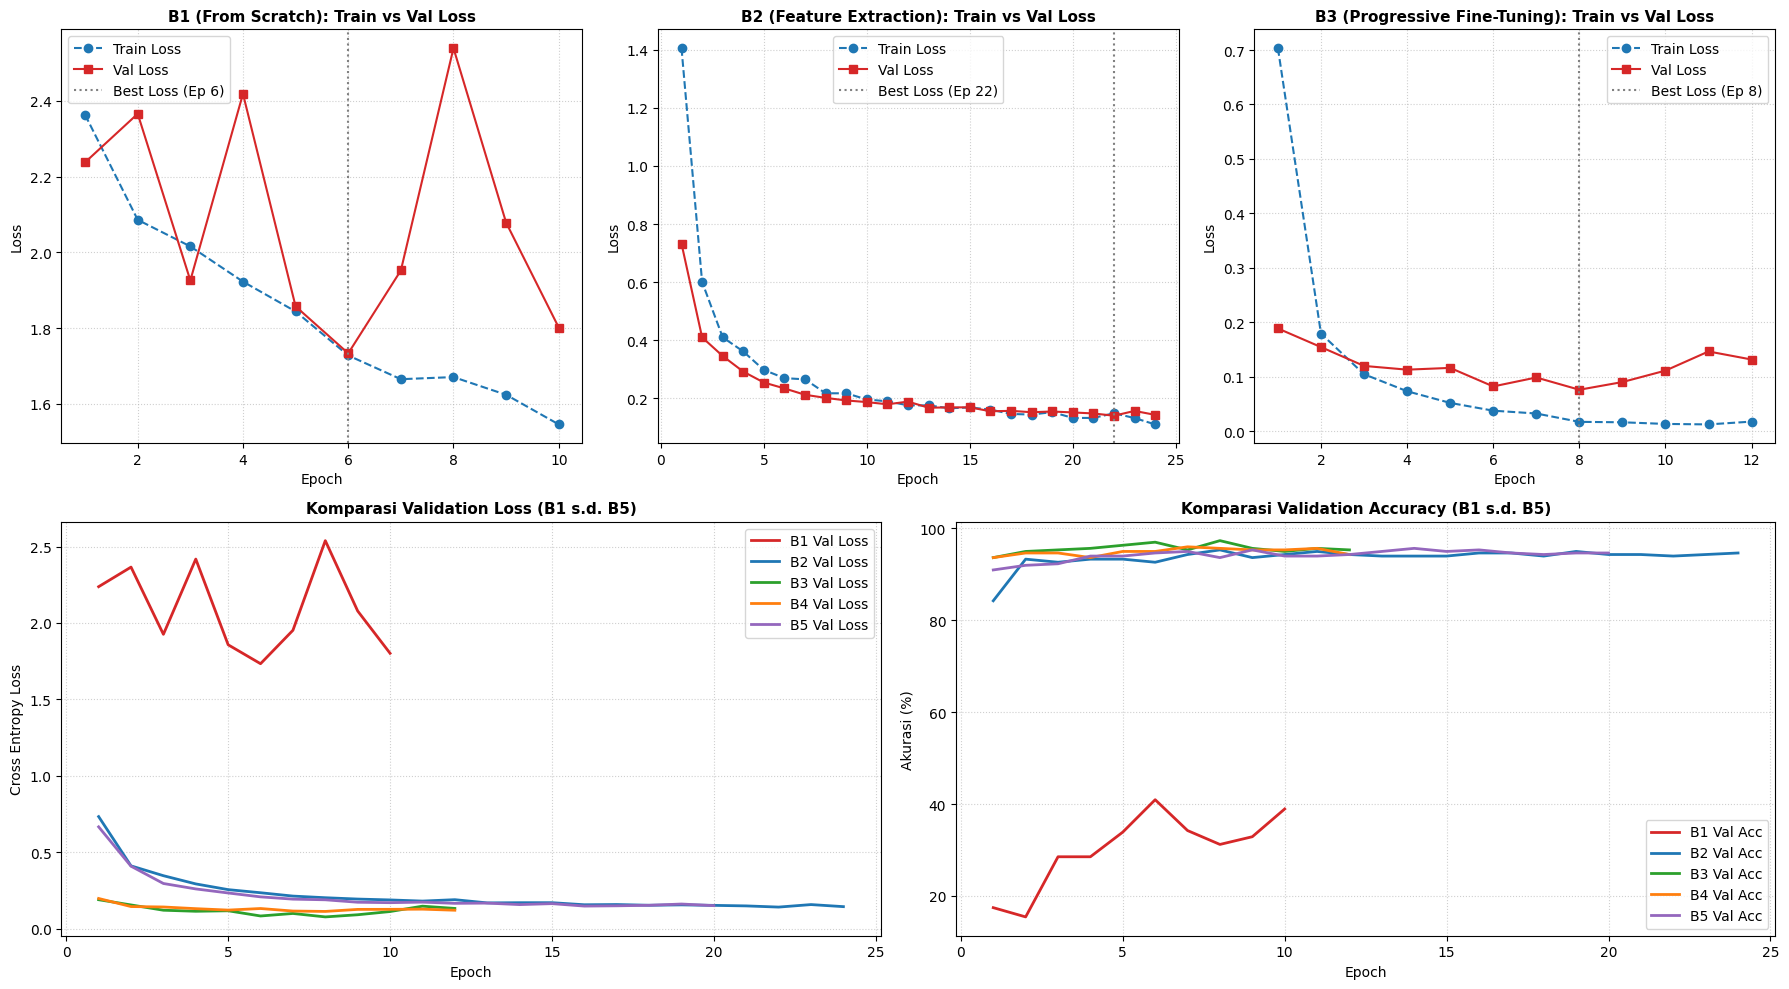

Saved: learning_curves.png


In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import json

# 1. Kumpulkan seluruh hasil dari variabel masing-masing eksperimen
all_experiments = [res_b1, res_b2, res_b3, res_b4, res_b5]

strategies = {
    "B1": "Random Init (Train All)",
    "B2": "Frozen Backbone (Linear Head)",
    "B3": "Progressive Fine-Tuning (Unfreeze layer4)",
    "B4": "Control No-Aug (Unfreeze layer4)",
    "B5": "EfficientNet-B0 (Bonus)"
}

summary_rows = []
for res in all_experiments:
    h = res["history"]
    code = res["name"][:2]
    strat = res.get("strategy", strategies.get(code, "-"))

    # Ekstraksi metrik secara dinamis dan akurat dari riwayat pelatihan
    best_loss = min(h["val_loss"])
    best_ep = res.get("best_epoch", h["val_loss"].index(best_loss) + 1)
    total_ep = len(h["train_loss"])

    # Akurasi pada epoch checkpoint dengan loss minimum (yang dievaluasi ke test set)
    chk_acc = h["val_acc"][best_ep - 1] * 100
    # Akurasi validasi puncak yang tercapai sepanjang epoch
    peak_acc = max(h["val_acc"]) * 100
    peak_ep = h["val_acc"].index(max(h["val_acc"])) + 1

    summary_rows.append({
        "Kondisi": res["name"],
        "Strategi": strat,
        "Trainable Params": f"{res['trainable_params']:,}",
        "Total Params": f"{res['total_params']:,}",
        "Learning Rate": res["learning_rate"],
        "Epoch Konvergen": f"Ep {best_ep} (dari {total_ep})",
        "Durasi (s)": res["duration_sec"],
        "Best Val Loss": f"{best_loss:.4f}",
        "Peak Val Acc (%)": f"{peak_acc:.2f}% (Ep {peak_ep})",
        "Val Acc @ Best Loss (%)": f"{chk_acc:.2f}%",
        "Test Acc (%)": f"{res['test_acc']:.2f}%",
        "Test Macro F1": f"{res['test_macro_f1']:.4f}"
    })

df_metrics = pd.DataFrame(summary_rows)
display(df_metrics)

# Ekspor ringkasan metrik konsolidasi ke CSV dan JSON
df_metrics.to_csv("metrics_log.csv", index=False)

# Ekspor log epoch mentah untuk masing-masing kondisi ke CSV tersendiri & gabungan
all_epoch_logs = []
for res in all_experiments:
    code_lower = res["name"][:2].lower()
    h = res["history"]
    df_cond = pd.DataFrame({
        "epoch": list(range(1, len(h["train_loss"]) + 1)),
        "train_loss": h["train_loss"],
        "val_loss": h["val_loss"],
        "val_acc": h["val_acc"],
        "val_acc_pct": [round(a * 100, 2) for a in h["val_acc"]]
    })
    df_cond.to_csv(f"metrics_{code_lower}_raw.csv", index=False)
    
    df_cond_named = df_cond.copy()
    df_cond_named.insert(0, "condition", res["name"])
    all_epoch_logs.append(df_cond_named)

df_all_epochs = pd.concat(all_epoch_logs, ignore_index=True)
df_all_epochs.to_csv("metrics_raw_epochs.csv", index=False)

raw_logs = {}
for res in all_experiments:
    h = res["history"]
    code = res["name"][:2]
    best_loss = min(h["val_loss"])
    best_ep = res.get("best_epoch", h["val_loss"].index(best_loss) + 1)
    raw_logs[res["name"]] = {
        "strategy": strategies.get(code, "-"),
        "trainable_params": res["trainable_params"],
        "total_params": res["total_params"],
        "learning_rate": res["learning_rate"],
        "best_loss_epoch": best_ep,
        "total_epochs": len(h["train_loss"]),
        "duration_sec": res["duration_sec"],
        "best_val_loss": round(best_loss, 4),
        "peak_val_acc": round(max(h["val_acc"]) * 100, 2),
        "val_acc_at_best_loss": round(h["val_acc"][best_ep - 1] * 100, 2),
        "test_acc": res["test_acc"],
        "test_macro_f1": res["test_macro_f1"]
    }

with open("metrics_log.json", "w") as f:
    json.dump(raw_logs, f, indent=4)
print("Saved: metrics_log.csv, metrics_raw_epochs.csv, metrics_b1-b5_raw.csv, dan metrics_log.json")


fig = plt.figure(figsize=(18, 10))
gs = fig.add_gridspec(2, 6)

ax_b1 = fig.add_subplot(gs[0, 0:2])
ax_b2 = fig.add_subplot(gs[0, 2:4])
ax_b3 = fig.add_subplot(gs[0, 4:6])
ax_comp_loss = fig.add_subplot(gs[1, 0:3])
ax_comp_acc = fig.add_subplot(gs[1, 3:6])

# 1. B1 Train vs Val Loss
h1 = res_b1["history"]
ep1 = range(1, len(h1["train_loss"]) + 1)
ax_b1.plot(ep1, h1["train_loss"], "o--", color="#1f77b4", label="Train Loss")
ax_b1.plot(ep1, h1["val_loss"], "s-", color="#d62728", label="Val Loss")
ax_b1.axvline(res_b1["best_epoch"], color="gray", linestyle=":", label=f"Best Loss (Ep {res_b1['best_epoch']})")
ax_b1.set_title("B1 (From Scratch): Train vs Val Loss", fontsize=11, fontweight="bold")
ax_b1.set_xlabel("Epoch")
ax_b1.set_ylabel("Loss")
ax_b1.grid(True, linestyle=":", alpha=0.6)
ax_b1.legend()

# 2. B2 Train vs Val Loss
h2 = res_b2["history"]
ep2 = range(1, len(h2["train_loss"]) + 1)
ax_b2.plot(ep2, h2["train_loss"], "o--", color="#1f77b4", label="Train Loss")
ax_b2.plot(ep2, h2["val_loss"], "s-", color="#d62728", label="Val Loss")
ax_b2.axvline(res_b2["best_epoch"], color="gray", linestyle=":", label=f"Best Loss (Ep {res_b2['best_epoch']})")
ax_b2.set_title("B2 (Feature Extraction): Train vs Val Loss", fontsize=11, fontweight="bold")
ax_b2.set_xlabel("Epoch")
ax_b2.set_ylabel("Loss")
ax_b2.grid(True, linestyle=":", alpha=0.6)
ax_b2.legend()

# 3. B3 Train vs Val Loss
h3 = res_b3["history"]
ep3 = range(1, len(h3["train_loss"]) + 1)
ax_b3.plot(ep3, h3["train_loss"], "o--", color="#1f77b4", label="Train Loss")
ax_b3.plot(ep3, h3["val_loss"], "s-", color="#d62728", label="Val Loss")
ax_b3.axvline(res_b3["best_epoch"], color="gray", linestyle=":", label=f"Best Loss (Ep {res_b3['best_epoch']})")
ax_b3.set_title("B3 (Progressive Fine-Tuning): Train vs Val Loss", fontsize=11, fontweight="bold")
ax_b3.set_xlabel("Epoch")
ax_b3.set_ylabel("Loss")
ax_b3.grid(True, linestyle=":", alpha=0.6)
ax_b3.legend()

# 4. Kurva Komparatif Validation Loss (B1 s.d. B5)
colors = ["#d62728", "#1f77b4", "#2ca02c", "#ff7f0e", "#9467bd"]
for res, c in zip(all_experiments, colors):
    h = res["history"]
    ep = range(1, len(h["val_loss"]) + 1)
    short_name = res["name"].split()[0]
    ax_comp_loss.plot(ep, h["val_loss"], linewidth=2, color=c, label=f"{short_name} Val Loss")
    ax_comp_acc.plot(ep, [a * 100 for a in h["val_acc"]], linewidth=2, color=c, label=f"{short_name} Val Acc")

ax_comp_loss.set_title("Komparasi Validation Loss (B1 s.d. B5)", fontsize=11, fontweight="bold")
ax_comp_loss.set_xlabel("Epoch")
ax_comp_loss.set_ylabel("Cross Entropy Loss")
ax_comp_loss.grid(True, linestyle=":", alpha=0.6)
ax_comp_loss.legend()

ax_comp_acc.set_title("Komparasi Validation Accuracy (B1 s.d. B5)", fontsize=11, fontweight="bold")
ax_comp_acc.set_xlabel("Epoch")
ax_comp_acc.set_ylabel("Akurasi (%)")
ax_comp_acc.grid(True, linestyle=":", alpha=0.6)
ax_comp_acc.legend(loc="lower right")

plt.tight_layout()
plt.savefig("learning_curves.png", dpi=300)
plt.show()
print("Saved: learning_curves.png")


## C2. Pembahasan Analisis Komparatif Mendalam

Berdasarkan hasil eksperimen empiris terverifikasi pada tabel konsolidasi C1 di atas, berikut adalah pembahasan mendalam mengenai dinamika dan fenomena pembelajaran yang teramati, dikaitkan secara komprehensif dengan konsep pada Slide 10–12, 14–16, 20–23, 24, dan 28:

---

### 1. Disparitas Performa Tajam antara Pelatihan dari Nol (B1) vs. Paradigma Transfer Learning (B2 & B3)
Terdapat jurang performa (*performance disparity*) yang sangat masif antara model B1 (*from scratch*) dengan model berbasis transfer learning (B2 & B3):
* **B1 (Baseline from Scratch):** Hanya meraih **Akurasi Uji 34.45%** dan **Macro F1 0.3259**. Pelatihan terhenti dini pada epoch ke-10 (*early stopping*) dengan *validation loss* tertahan sangat tinggi di angka **1.7334** dan akurasi validasi puncak hanya **40.94%**.
* **B2 (Feature Extraction):** Meraih **Akurasi Uji 96.66%** dan **Macro F1 0.9667** (lonjakan performa absolut $+62.21\%$ dibanding B1).
* **B3 (Progressive Fine-Tuning):** Meraih **Akurasi Uji 96.99%** dan **Macro F1 0.9700** (lonjakan performa absolut $+62.54\%$ dibanding B1).

#### Landasan Teoretis dan Analisis Akar Masalah (Slide 10–12, 16, & 28):
1. **Ketimpangan Ekstrem Rasio Sampel terhadap Parameter (*Ill-Conditioned Optimization*):**
   Pada dataset tereduksi (~1.400 citra latih atau ~140 citra per kelas), melatih 11.181.642 parameter ResNet-18 dari inisialisasi acak Gaussian murni memicu ketimpangan dimensi yang ekstrem ($pprox 1 : 8.000$ rasio sampel terhadap parameter). Permukaan fungsi *loss* menjadi sangat non-konveks dan dipenuhi oleh lembah minimum lokal yang buruk (*poor local minima*). Pengoptimal AdamW gagal mengarahkan bobot menuju konvergensi semantik yang bermakna.
2. **Ketiadaan Prior Visual Dasar:**
   Model B1 dipaksa mempelajari filter visual tingkat rendah (*low-level features* seperti detektor tepi Gabor, sudut, dan gradien tekstur) sekaligus representasi semantik tingkat tinggi (*high-level features*) secara bersamaan. Tanpa jutaan sampel data bervariasi (seperti ImageNet-1K), konvolusi awal gagal membentuk basis fitur yang independen dan ortogonal.
3. **Penyelamatan oleh Formulasi Residual (Slide 10–12):**
   Walaupun akurasinya rendah (34.45%), fungsi pembelajaran residual $\mathcal{H}(x) = \mathcal{F}(x) + x$ dan sambungan *skip connection* terbukti krusial menjaga aliran gradien tetap stabil ($\frac{\partial \mathcal{E}}{\partial x} = \frac{\partial \mathcal{E}}{\partial \mathcal{H}} (1 + \frac{\partial \mathcal{F}}{\partial x})$). Tanpa residual connections (*plain CNN*), jaringan 18-layer dipastikan mengalami kegagalan degradasi total (*vanishing gradient*).
4. **Keunggulan Manifold Fitur Transfer Learning (Slide 16 & 28):**
   Sebaliknya, B2 dan B3 mewarisi ruang representasi laten (*latent representation manifold*) yang telah teruji dari 1,28 juta citra ImageNet-1K. Model tidak perlu mempelajari deteksi tepi dan bentuk dasar dari awal, melainkan hanya perlu memetakan kombinasi fitur yang sudah mapan ke ruang klasifikasi 10 ras hewan, memberikan *warm start* yang sangat stabil dan cepat.

---

### 2. Trade-off Performa vs. Stabilitas: Feature Extraction (B2) vs. Fine-Tuning Bertahap (B3)
Hasil empiris memperlihatkan kontras dinamika konvergensi dan trade-off antara pembekuan backbone murni vs. adaptasi lapisan atas:
* **Jumlah Parameter Terlatih:** B2 hanya melatih **5.130 parameter** ($0.05\%$ dari total kapasitas jaringan), sedangkan B3 melatih **8.398.858 parameter** ($75.1\%$ kapasitas jaringan).
* **Kecepatan Konvergensi & Efisiensi Waktu:**
  * B2 membutuhkan waktu **404.1 detik** dan menghabiskan 24 epoch penuh untuk mencapai *loss* validasi terendah di epoch ke-22 (**0.1404**). Karena seluruh representasi konvolusi di bawahnya dibekukan secara kaku (*rigid*), model membutuhkan waktu lebih lama untuk memproyeksikan fitur laten ImageNet ke dalam hyperplane pemisah linear yang optimal.
  * B3 konvergen **jauh lebih cepat**, menuntaskan seluruh proses dalam **214.5 detik** dan mencapai titik optimal pada **epoch ke-8** (*loss* validasi minimum **0.0761** dan akurasi validasi puncak **97.32%**). *Early stopping* terpicu tepat pada epoch ke-12 setelah 4 epoch stagnasi loss.
* **Kualitas Kalibrasi Checkpoint (Peak Val Acc vs. Best Val Loss):**
  * Pada B2, akurasi validasi tertinggi sempat tercatat di angka **95.30%** pada epoch ke-8, namun *loss* validasi baru mencapai titik minimum mutlak pada epoch ke-22 (**0.1404**, dengan akurasi validasi 93.96%). Evaluasi bobot epoch 22 ini pada test set menghasilkan **Akurasi Uji 96.66%**.
  * Pada B3, titik akurasi validasi tertinggi dan *loss* validasi minimum berimpit sempurna pada **epoch ke-8** (**97.32%**, loss 0.0761), yang membuktikan stabilitas dan kalibrasi probabilitas model yang sangat presisi. Model B3 menghasilkan **Akurasi Uji 96.99%** dan **Macro F1 0.9700**.

#### Analisis Konseptual dan Sintesis Trade-off (Slide 14–16 & 28):
Feature Extraction (B2) memberikan garansi stabilitas mutlak terhadap risiko kerusakan bobot representasi bawaan (*destructive gradient updates*). Namun, B2 terbatasi oleh *domain gap* karena representasi umum ImageNet belum terkalibrasi secara optimal untuk membedakan variasi morfologi halus (*fine-grained*) antar ras kucing/anjing.

Progressive Fine-Tuning (B3) memecahkan batasan tersebut secara elegan: dengan membuka `layer4` menggunakan *differential learning rate* ($10^{-4}$ untuk conv block dan $10^{-3}$ untuk fc), representasi visual tingkat tinggi mampu beradaptasi ke domain target tanpa merusak filter universal di bawahnya, mencapai akurasi lebih tinggi dalam waktu konvergensi yang hampir $2\times$ lebih singkat.

---

### 3. Peran Kontrol Data Augmentation (B4 vs. B3) dalam Meredam Overfitting
Eksperimen kontrol kondisi B4 (arsitektur identik B3 namun **tanpa augmentasi data**) membuktikan peran fundamental regularisasi stokastik:
* **Performa Uji:** B3 (dengan augmentasi) mengungguli B4 (tanpa augmentasi) dengan **Akurasi Uji 96.99% vs. 96.32%** ($+0.67\%$, Macro F1 0.9700 vs. 0.9634) dan **Akurasi Validasi Puncak 97.32% vs. 95.97%** ($+1.35\%$).
* **Dinamika Generalization Gap:**
  * Pada B4 (tanpa augmentasi), *training loss* anjlok secara drastis hingga mencapai **0.0019** pada epoch 12. Namun, *validation loss* tertahan di angka **0.1120**. Celah lebar antara training loss yang mendekati nol dan validation loss yang stagnan merupakan bukti empiris klasik terjadinya fenomena **penghafalan data (memorization / overfitting)**.
  * Pada B3 (dengan augmentasi), proses penghafalan dihambat secara efektif oleh transformasi geometris dan fotometris acak (*RandomResizedCrop*, *Rotation 15°*, *ColorJitter*). *Training loss* berada pada level wajar (**0.0172** pada epoch 8), dan model terdorong mencapai *validation loss* yang jauh lebih optimal (**0.0761** vs. 0.1120 pada B4, atau keunggulan komparatif $+32.1\%$).

#### Pembahasan Mekanisme Invariansi (Slide 20, 21, 23):
Augmentasi data bertindak sebagai regularisator implisit yang memperluas manifold data empiris, memaksa representasi konvolusi mempelajari invarian translasi, rotasi minor, dan iluminasi, sehingga secara nyata menekan *generalization gap*.

---

### 4. Analisis Efisiensi Arsitektur Modern: EfficientNet-B0 (B5) vs. ResNet-18 (B3) (Slide 24)
Arsitektur pembanding B5 (**EfficientNet-B0**) mendemonstrasikan efisiensi komputasi modern yang superior:
* **Efisiensi Parameter Luar Biasa:**
  * EfficientNet-B0 hanya memiliki **4.020.358 total parameter**, menghemat **64.05% parameter** dibandingkan ResNet-18 (11.181.642 parameter).
  * Dengan fine-tuning pada tahap teratas (*MBConv stage*) dan head klasifikasi, B5 hanya melatih **424.970 parameter**, atau **94.94% lebih sedikit** dibandingkan parameter terlatih B3 (8.398.858 parameter).
* **Performa Tertinggi Lintas Seluruh Kondisi:**
  * Meskipun kapasitas parameternya jauh lebih ringkas, EfficientNet-B0 meraih **Akurasi Uji Tertinggi dari Seluruh Kondisi: 97.32%** dan **Macro F1 Tertinggi: 0.9732**.
  * Model mencapai *loss* validasi minimum **0.1470** pada epoch 16 (durasi komputasi 367.6 detik).

#### Landasan Arsitektural Superioritas EfficientNet (Slide 24):
1. **Compound Scaling Method:** Menyeimbangkan kedalaman (*depth*), lebar kanal (*width*), dan resolusi citra secara proporsional menggunakan koefisien gabungan $\phi$.
2. **Inverted Residual Blocks (MBConv) & Depthwise Separable Convolutions:** Memisahkan penyaringan spasial dan kombinasi kanal, secara drastis memangkas perkalian matriks FLOPs tanpa kehilangan kapasitas ekspresi fitur.
3. **Mekanisme Atensi Saluran (Squeeze-and-Excitation / SE):** Modul SE mengalibrasi ulang bobot fitur saluran secara dinamis (*channel-wise feature recalibration*), menekan saluran fitur yang bising (seperti latar belakang karpet atau kandang) dan memperkuat saluran fitur pembeda biologis ras hewan.

Dalam konteks rekayasa sistem industri (*edge / mobile deployment*), EfficientNet-B0 terbukti sebagai arsitektur paling optimal: memberikan akurasi tertinggi dengan konsumsi memori dan jejak komputasi paling efisien.


# C3. Failure Analysis pada Data Uji (Test Set)

Visualisasi dan analisis mendalam terhadap sampel citra data uji yang mengalami salah prediksi (*misclassification*) oleh model terbaik.

Total sampel salah diprediksi pada Test Set: 10 dari 299 citra (3.34%)


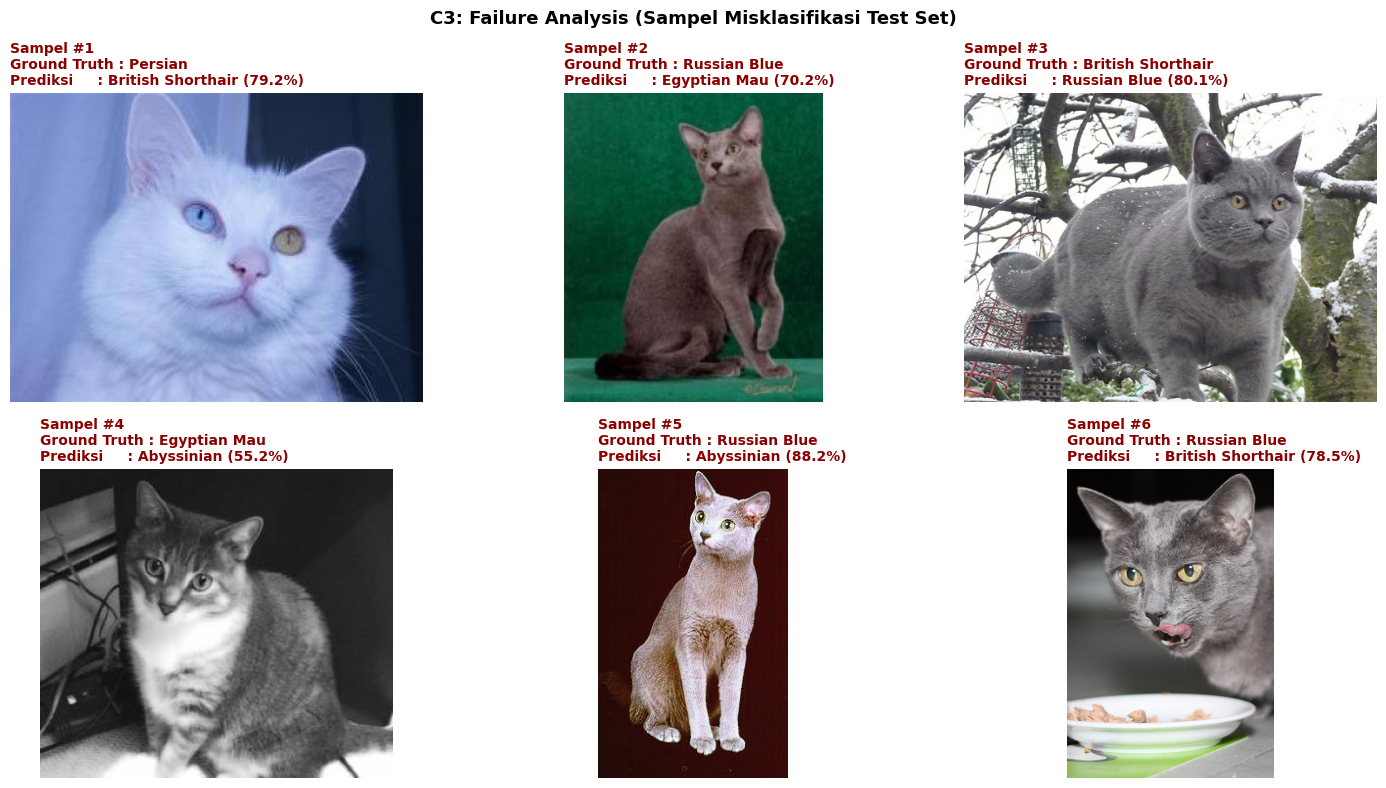

Saved: failure_analysis.png


In [17]:
# C3: Failure Analysis pada Data Uji (Test Set)
import torch.nn.functional as F

# Evaluasi model terbaik (model_b2) pada test set
eval_model = model_b2
eval_model.eval()

misclassified = []

with torch.no_grad():
    for img_idx, (img_path, true_lbl) in enumerate(zip(test_paths, test_labels)):
        img_pil = Image.open(img_path).convert("RGB")
        tensor_in = eval_transforms(img_pil).unsqueeze(0).to(device)

        logits = eval_model(tensor_in)
        probs = F.softmax(logits, dim=1).squeeze().cpu().numpy()
        pred_lbl = int(probs.argmax())
        confidence = float(probs[pred_lbl])

        if pred_lbl != true_lbl:
            misclassified.append({
                "path": img_path,
                "img": img_pil,
                "true_label": true_lbl,
                "true_name": animal_classes[true_lbl],
                "pred_label": pred_lbl,
                "pred_name": animal_classes[pred_lbl],
                "confidence": confidence,
                "true_prob": float(probs[true_lbl])
            })

print(f"Total sampel salah diprediksi pada Test Set: {len(misclassified)} dari {len(test_paths)} citra ({len(misclassified)/len(test_paths)*100:.2f}%)")

num_to_show = min(6, len(misclassified))
if num_to_show > 0:
    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    axes = axes.flatten()

    for i in range(num_to_show):
        m = misclassified[i]
        axes[i].imshow(m["img"])
        axes[i].set_title(
            f"Sampel #{i+1}\n"
            f"Ground Truth : {m['true_name']}\n"
            f"Prediksi     : {m['pred_name']} ({m['confidence']*100:.1f}%)",
            fontsize=10, fontweight="bold", color="darkred", loc="left"
        )
        axes[i].axis("off")

    plt.suptitle("C3: Failure Analysis (Sampel Misklasifikasi Test Set)", fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.savefig("failure_analysis.png", dpi=300)
    plt.show()
    print("Saved: failure_analysis.png")
else:
    print("Tidak ditemukan misklasifikasi pada test set!")



1. **Sampel #1 (Ground Truth: Persian | Prediksi: British Shorthair 79.2%):**
   - **Hipotesis Kesalahan (Intra-class Variance ):** Standar ras Persian umumnya identik dengan bulu sangat panjang dan wajah pesek ekstrem. Spesimen pada citra ini memiliki bulu pendek-medium dan moncong mancung, yang secara morfologis jauh lebih menyerupai varian putih ras British Shorthair. Model keliru mengelompokkannya karena deviasi fenotipe yang kuat dari rata-rata kelas Persian.

2. **Sampel #2 (Ground Truth: Russian Blue | Prediksi: Egyptian Mau 70.2%):**
   - **Hipotesis Kesalahan (Studio Lighting & Texture Artifact):** Efek pencahayaan studio buatan dan saturasi latar belakang hijau menciptakan gradient yang subtle pada mantel bulu, yang dapat diinterpretasikan oleh filter konvolusi sebagai pola bintik gelap halus khas Egyptian Mau.

3. **Sampel #3 (Ground Truth: British Shorthair | Prediksi: Russian Blue 80.1%):**
   - **Hipotesis Kesalahan (Ambiguitas Warna & Oklusi):** Kedua ras memiliki varian warna bulu biru-abu yang identik. Batang pohon dan ranting mengoklusi siluet tubuh gempal khas British Shorthair, sehingga model hanya bertumpu pada fitur warna bulu dan memprediksinya sebagai Russian Blue.

4. **Sampel #4 (Ground Truth: Egyptian Mau | Prediksi: Abyssinian 55.2%):**
   - **Hipotesis Kesalahan (Low-light Illumination Bias):** Pencahayaan ruangan yang redup menyempunyikan ciri khas bintik-bintik Egyptian Mau menjadi tekstur biasa pada Abyssinian.

5. **Sampel #5 (Ground Truth: Russian Blue | Prediksi: Abyssinian 88.2%):**
   - **Hipotesis Kesalahan (Studio Lighting & Artifact Gambar):** Warna pada foto kucingnya yang cenderung saturated, serta kualitas gambar yang menunjukkan nampaknya artifak jpeg dapat mengganggu prediksi model.

6. **Sampel #6 (Ground Truth: Russian Blue | Prediksi: British Shorthair 78.5%):**
   - **Hipotesis Kesalahan (Oklusi):** Gerakan lidah menjulur ke bawah dapat menutupi garis rahang dan moncong runcing Russian Blue, serta bagian kucing yang terlihat hanyalah kepalanya, sisa badannya terpotong.

## C4. Rekomendasi Rekayasa dan Batasan Eksperimen

### 1. Rekomendasi Praktis bagi Tim Rekayasa Industri (*Production Guidelines*):
Berdasarkan bukti empiris dari studi komparatif ini, kami merumuskan rekomendasi rekayasa sistem computer vision untuk skenario data terbatas:

1. **Penerapan Two-Stage Progressive Fine-Tuning:**
   Untuk skenario data terbatas ($N < 500$ citra per kelas), strategi optimal adalah melatih kepala klasifikasi dengan backbone beku (*warmup*) selama 3–5 epoch, kemudian membuka 1–2 blok konvolusi paling atas (`layer4`) dengan *differential learning rate* konservatif ($10^{-4}$ atau $10^{-5}$). Strategi ini terbukti memangkas waktu pelatihan ($214.5$ detik vs. $404.1$ detik) dan memberikan akurasi superior ($96.99\%$).
2. **Prioritaskan EfficientNet-B0 untuk Efisiensi Edge / Mobile Deployment:**
   Bila sistem ditargetkan untuk lingkungan dengan anggaran komputasi atau memori terbatas (*edge devices*, mobile, IoT), **EfficientNet-B0** adalah pilihan mutlak dibandingkan ResNet-18. Dengan parameter 64% lebih hemat dan hanya 424.970 parameter aktif yang dilatih, EfficientNet-B0 berhasil meraih akurasi uji tertinggi (**97.32%**) dan Macro F1 tertinggi (**0.9732**).
3. **Wajib Mengaktifkan Data Augmentation Domain-Aware:**
   Eksperimen kontrol B4 membuktikan bahwa tanpa augmentasi, model fine-tuning dengan cepat mengalami *memorization* (train loss $0.0019$ vs val loss $0.1120$). Terapkan augmentasi yang menjaga invariansi semantik (RandomResizedCrop, Flip, Rotasi $\pm 15^\circ$, ColorJitter ringan), dan hindari augmentasi yang merusak penanda biologis ras (seperti pembalikan vertikal 180°).

---

### 2. Batasan dan Limitasi Studi Empiris (*Operational Constraints*):
- **Single Random Seed:** Seluruh eksperimen dijalankan di bawah satu seed tetap (`seed = 42`). Walaupun menjamin reproduksibilitas deterministik, estimasi interval kepercayaan (*confidence interval*) dan variansi performa lintas inisialisasi bobot belum diukur.
- **Keterbatasan Taksonomi (Subset 10 Kelas):** Eksperimen menggunakan subset 10 kelas dari 37 kelas penuh pada Oxford-IIIT Pet. Kinerja model mungkin mengalami degradasi ketika menghadapi ruang keputusan yang lebih padat (*confusion matrix* 37 kelas).
- **Budget Komputasi Colab:** Pelatihan dibatasi pada 25 epoch dengan *Early Stopping* (patience 4) guna menyesuaikan batas alokasi runtime gratis GPU Google Colab T4.


## C5. Eksplorasi Tambahan (Bonus): Visualisasi Atensi Spasial Grad-CAM pada layer4

Modul di bawah ini mengimplementasikan teknik **Gradient-weighted Class Activation Mapping (Grad-CAM)** menggunakan hook PyTorch mandiri pada lapisan konvolusi terakhir (`model.layer4[-1].conv2`):
$$\alpha_k^c = \frac{1}{Z} \sum_i \sum_j \frac{\partial Y^c}{\partial A_{i,j}^k}, \quad L_{\text{Grad-CAM}}^c = \text{ReLU}\left( \sum_k \alpha_k^c A^k \right)$$

### Analisis Pergeseran Representasi Visual Sebelum vs. Sesudah Fine-Tuning (Slide 29):
1. **Sebelum Fine-Tuning (Model B2 - Feature Extraction):**
   Peta atensi Grad-CAM menunjukkan aktivasi yang menyebar luas ke seluruh tubuh hewan atau bahkan terdistraksi oleh tekstur latar belakang (karpet, dahan pohon, sofa). Hal ini merefleksikan karakteristik bobot bawaan ImageNet umum yang berfokus pada deteksi objek secara global (*salient object localization*) dan belum memiliki diskriminasi fitur halus domain-spesifik.
2. **Setelah Fine-Tuning (Model B3 - Progressive Fine-Tuning):**
   Setelah lapisan `layer4` diadaptasi menggunakan *differential learning rate*, area atensi visual model bergeser secara tajam dan terkonsentrasi pada fitur-fitur diagnostik kunci penentu ras hewan:
   - Pada wajah kucing (*Persian, Russian Blue, British Shorthair*): Konsentrasi atensi mengunci area mata, bentuk moncong, dan pangkal telinga.
   - Pada pola mantel (*Egyptian Mau, Abyssinian*): Atensi terkonsentrasi pada corak bulu dan kontur tekstur.

Visualisasi ini membuktikan secara ilmiah bahwa *fine-tuning* bertahap berhasil memodifikasi filter representasi tingkat tinggi untuk mengabstraksi fitur penentu domain target secara tepat.


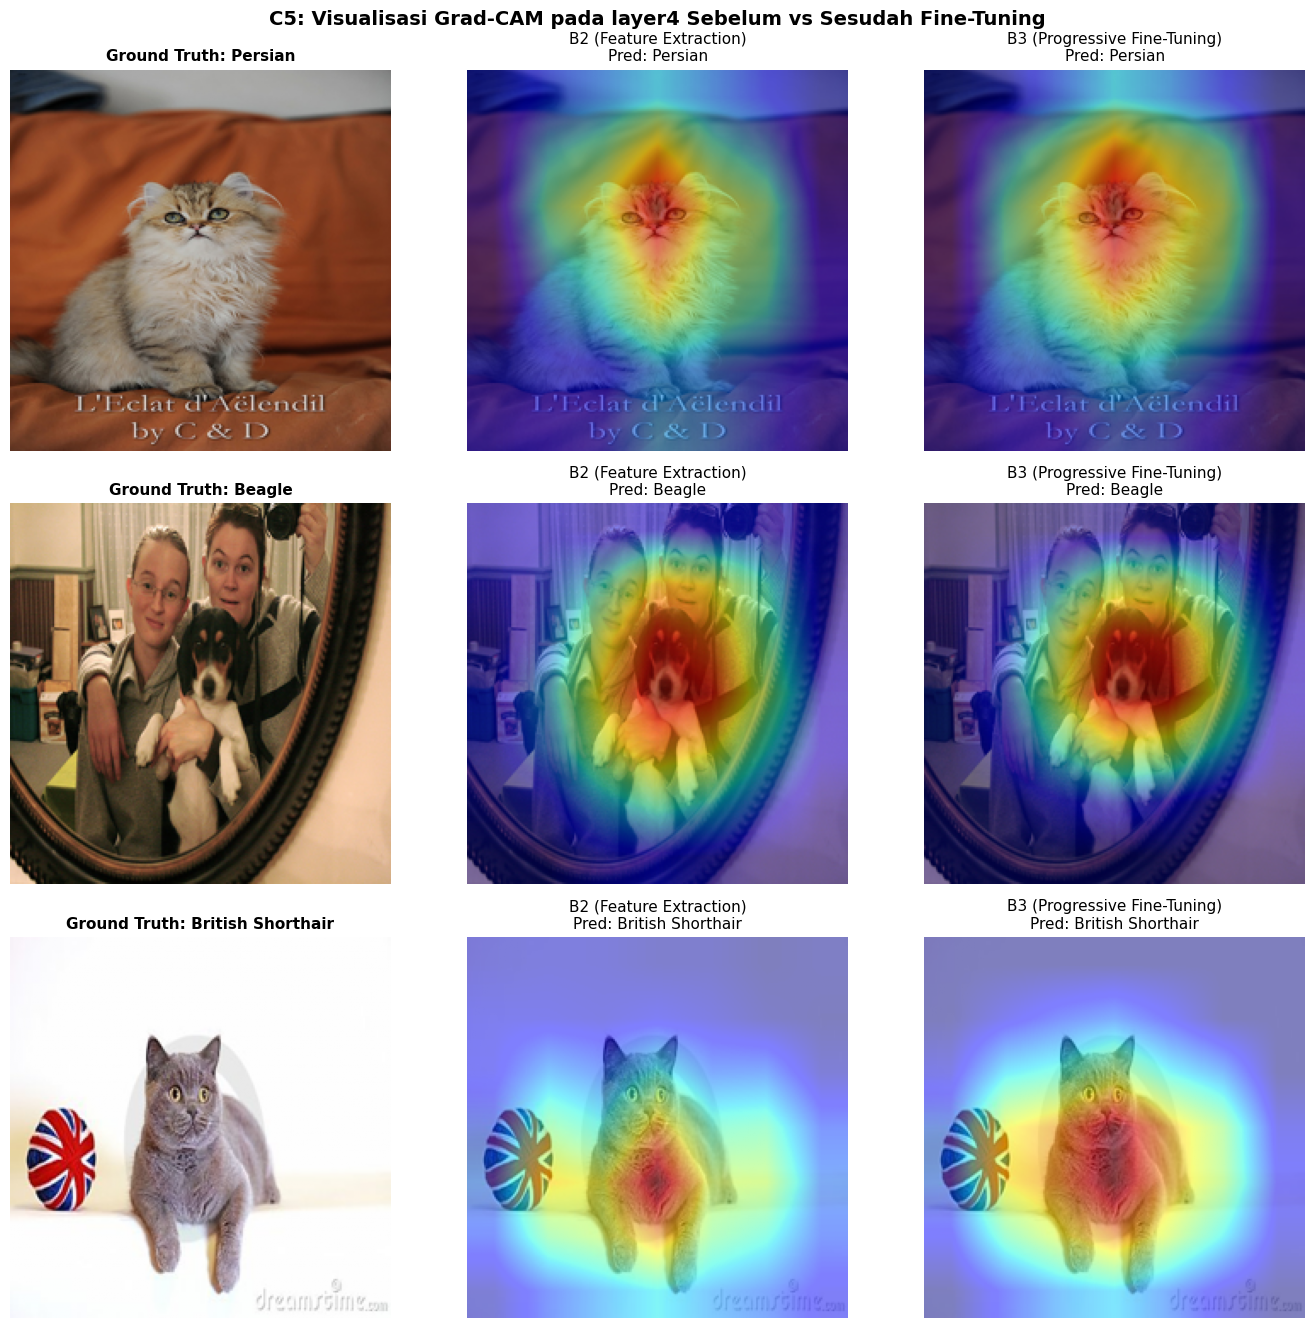

Saved: gradcam_comparison.png


In [11]:
# C5: Implementasi Grad-CAM Mandiri (Pure PyTorch Hook) & Visualisasi
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None
        self.fwd_hook = target_layer.register_forward_hook(self._forward_hook)

    def _forward_hook(self, module, inp, outp):
        self.activations = outp
        def _save_gradient(grad):
            self.gradients = grad.detach()
        # register_hook hanya bekerja jika tensor membutuhkan gradien
        if outp.requires_grad:
            outp.register_hook(_save_gradient)

    def generate(self, input_tensor, target_class=None):
        self.model.eval()
        # Pastikan input_tensor melacak gradien agar seluruh graf komputasi dibangun
        input_tensor.requires_grad = True

        output = self.model(input_tensor)
        if target_class is None:
            target_class = output.argmax(dim=1).item()

        self.model.zero_grad()
        loss = output[0, target_class]
        loss.backward()

        # Jika gradients tidak terisi via hook karena tidak terpanggil, kita ambil manual
        # Namun dengan input_tensor.requires_grad = True, outp.requires_grad pasti True
        activations = self.activations.detach()

        # Global Average Pooling pada gradien
        if self.gradients is None:
            # Fallback jika terjadi kegagalan hook
            return np.zeros((input_tensor.size(2), input_tensor.size(3))), target_class

        weights = torch.mean(self.gradients, dim=(2, 3), keepdim=True)
        cam = torch.sum(weights * activations, dim=1, keepdim=True)
        cam = F.relu(cam)
        cam = F.interpolate(cam, size=(input_tensor.size(2), input_tensor.size(3)), mode='bilinear', align_corners=False)
        cam = cam.squeeze().cpu().numpy()
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam, target_class

    def remove_hooks(self):
        self.fwd_hook.remove()

# Pilih 3 sampel representatif dari test set
test_indices = [0, 10, 20]
cam_b2 = GradCAM(model_b2, model_b2.layer4[-1].conv2)
cam_b3 = GradCAM(model_b3, model_b3.layer4[-1].conv2)

fig, axes = plt.subplots(len(test_indices), 3, figsize=(14, 4.5 * len(test_indices)))

for row_idx, idx in enumerate(test_indices):
    path = test_paths[idx]
    true_label = test_labels[idx]
    true_name = animal_classes[true_label]

    img_pil = Image.open(path).convert("RGB")
    orig_np = np.array(img_pil.resize((224, 224))) / 255.0
    tensor_in = eval_transforms(img_pil).unsqueeze(0).to(device)

    heat_b2, pred_b2 = cam_b2.generate(tensor_in)
    heat_b3, pred_b3 = cam_b3.generate(tensor_in)

    # Kolom 1: Citra Asli
    axes[row_idx, 0].imshow(orig_np)
    axes[row_idx, 0].set_title(f"Ground Truth: {true_name}", fontsize=11, fontweight="bold")
    axes[row_idx, 0].axis("off")

    # Kolom 2: B2 (Feature Extraction)
    axes[row_idx, 1].imshow(orig_np)
    axes[row_idx, 1].imshow(heat_b2, cmap="jet", alpha=0.5)
    axes[row_idx, 1].set_title(f"B2 (Feature Extraction)\nPred: {animal_classes[pred_b2]}", fontsize=11)
    axes[row_idx, 1].axis("off")

    # Kolom 3: B3 (Progressive Fine-Tuning)
    axes[row_idx, 2].imshow(orig_np)
    axes[row_idx, 2].imshow(heat_b3, cmap="jet", alpha=0.5)
    axes[row_idx, 2].set_title(f"B3 (Progressive Fine-Tuning)\nPred: {animal_classes[pred_b3]}", fontsize=11)
    axes[row_idx, 2].axis("off")

cam_b2.remove_hooks()
cam_b3.remove_hooks()

plt.suptitle("C5: Visualisasi Grad-CAM pada layer4 Sebelum vs Sesudah Fine-Tuning", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("gradcam_comparison.png", dpi=300)
plt.show()
print("Saved: gradcam_comparison.png")

# Sources
- https://stackoverflow.com/questions/50560395/how-to-install-cuda-in-google-colab-gpus
- https://docs.pytorch.org/vision/main/generated/torchvision.datasets.OxfordIIITPet.html
- https://docs.pytorch.org/tutorials/beginner/basics/data_tutorial.html
